<h1 align="center">Before the Shelf Runs Empty</h1>
<h3 align="center">Safety Stock and Reorder Point Under Uncertain Demand</h3>
<p align="center"><em>Math Concepts for Developers, Final Project</em></p>

## 1. Introduction and Research Questions

An online retailer of bathroom and kitchen products keeps part of its assortment in its own warehouse. When the stock of a product runs low, a purchase order goes to the supplier, who needs a fixed number of days to deliver: the **lead time**. During those days the product keeps selling. If more is sold than was on the shelf when the order was placed, the product runs out, and customers either wait or buy elsewhere.

The ordering system therefore has to pick a stock level, the **reorder point** $R$, at which the next purchase order is triggered. Picking it is a trade-off:

- too low, and the product is regularly out of stock before the supplier delivers;
- too high, and money sits on the shelf as inventory that will not be needed for weeks.

The retailer's current ordering system uses a fixed rule of thumb per product. This project asks what the rule *should* be, and how much of the reorder point exists only because demand is uncertain.

### From the warehouse to mathematics

Let $D_1, D_2, \dots$ be the number of units sold on consecutive days. The sales on a given day cannot be predicted, so each $D_i$ is a **random variable**. If the supplier needs $L$ days, the demand we must survive after placing an order is the sum

$$X = D_1 + D_2 + \dots + D_L = \sum_{i=1}^{L} D_i .$$

We do not run out during the lead time exactly when $X \le R$. The quality of a reorder point is therefore the probability

$$\alpha = P(X \le R),$$

called the **service level**. A service level of 95 % means that in 19 lead times out of 20 the stock lasts until the delivery arrives.

The reorder point splits naturally into two parts:

$$R = \underbrace{E[X]}_{\text{expected demand during the lead time}} + \underbrace{SS}_{\text{safety stock}} .$$

The first part would be enough in a world without randomness. The second part, the **safety stock** $SS$, exists only to absorb the days when demand is above average. The question of this project is: given daily sales data and a target service level, how large should $SS$ be, and what does it cost?

### Hypotheses

Three statements to test along the way, so that the end of the notebook can say which held:

1. **Safety stock grows faster than the service level.** Going from 90 % to 95 % should cost less extra stock than going from 95 % to 99 %.
2. **Different demand patterns need different safety stock, even for the same average.** The intermittent product should need more safety stock *relative to its expected demand* than the steady one.
3. **The accuracy of the normal approximation depends on the lead time and on the demand pattern.** The longer the lead time, the closer the demand during it should be to a normal distribution; a short lead time and an irregular daily demand should produce the largest errors.

### Assumptions

Every model simplifies. These are the simplifications made here, stated up front so that the results can be judged against them:

1. **Daily demands are independent of each other and share one distribution** for a given product. This is checked informally against the data in section 3, and its limits are discussed in the conclusions.
2. **The lead time is fixed and known.** We use the delivery time the supplier quotes for each product: 10, 180 and 63 days for products A, B and C.
3. **A day without a sale is a day with zero demand**, not missing data. The sales export lists only days with at least one sale.
4. **Unmet demand is lost.** A customer who finds the product out of stock buys elsewhere; the sale is not postponed.
5. **Only the reorder point is studied.** How much to order each time is a separate question and is kept fixed. The reorder point is compared with the *inventory position*, stock on hand plus units already ordered from the supplier, so that an order already on its way is not placed twice.
6. **Wholesale orders stay in the data.** One day in product C carries a single order of 40 units from a business customer, mirroring a real event. It is kept, and its effect is shown explicitly rather than removed silently.
7. **All three products are analysed over the same window: 2026-04-01 to 2026-10-31, 214 days.** This is the period in which the three real products behind the data were all regularly on sale.
8. **The data is synthetic, calibrated on real sales.** The retailer's sales export could not be published, so the notebook runs on generated series with the same statistical profile as three real products; section 2 explains how they were built.

## 2. Dataset Description and Preparation

The analysis was designed on a real export from the retailer's order database. That export could not be published, so the repository contains **synthetic daily sales with the same statistical profile**. Each day of each product was generated with two random experiments:

1. a **Bernoulli trial**: does the product sell at all today? A sale day happens with probability $q$;
2. on a sale day, the number of units is drawn from a **probability mass function**: a table $p(1), p(2), \dots$ with the probability of each quantity.

The value of $q$ and the table were set per product to match the share of sale days and the distribution of daily units of the real product. Product C additionally contains one wholesale order of 40 units on a single day (assumption 6).

The file has three columns:

| Column | Meaning |
|---|---|
| `sale_date` | calendar day, `YYYY-MM-DD` |
| `product` | `A`, `B` or `C` |
| `units` | units of that product sold on that day |

It covers 2026-04-01 to 2026-10-31, 214 days (assumption 7). As in the real export, **days without a sale are not listed**: when loading, we build the complete calendar and fill in zero for the absent days (assumption 3).

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import matplotlib.dates as mdates

# One fixed colour per product, in a fixed order, so that A, B and C look the
# same on every chart in the notebook.
PRODUCT_COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}

# Supplier lead time in days, as quoted for each product.
LEAD_TIME_DAYS = {"A": 10, "B": 180, "C": 63}

DATA_PATH = "data/daily_sales.csv"
# The analysis window (assumption 7): the same 214 days for every product.
FIRST_DAY = np.datetime64("2026-04-01")
LAST_DAY = np.datetime64("2026-10-31")

# Chart defaults for the whole notebook, so that no chart has to repeat them.
plt.rcParams["figure.dpi"] = 110           # a bit sharper than the default 100
plt.rcParams["axes.spines.top"] = False    # no frame line above the plot area
plt.rcParams["axes.spines.right"] = False  # no frame line on the right side
plt.rcParams["axes.grid"] = True           # light grid lines behind the data
plt.rcParams["grid.alpha"] = 0.25          # and make them almost transparent


In [3]:
def show_table(headers, rows):
    """Render rows as a Markdown table: first column left-aligned, the rest right."""
    align = ["---:"] * len(headers)
    align[0] = ":---"
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(align) + " |"]
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))

In [4]:
def load_daily_sales(path, first_day, last_day):
    """Read the sales export and return (calendar, {product: units}).

    `calendar` holds every day from `first_day` to `last_day` inclusive and
    `units` has one entry per calendar day: the units sold on that day, with
    0 on days absent from the file.
    """
    raw = np.genfromtxt(
        path, delimiter=",", skip_header=1, encoding="utf-8",
        dtype=[("sale_date", "datetime64[D]"), ("product", "U1"), ("units", "f8")],
    )
    assert raw["sale_date"].min() >= first_day and raw["sale_date"].max() <= last_day
    calendar = np.arange(first_day, last_day + np.timedelta64(1, "D"), dtype="datetime64[D]")
    series = {}
    for product in np.unique(raw["product"]):
        rows = raw[raw["product"] == product]
        units = np.zeros(len(calendar))
        position = (rows["sale_date"] - first_day).astype(int)  # index of each sold day
        units[position] = rows["units"]
        series[product] = units
    return calendar, series


DAYS, sales = load_daily_sales(DATA_PATH, FIRST_DAY, LAST_DAY)
PRODUCTS = list(sales)  # ['A', 'B', 'C']
display(Markdown(f"**{len(DAYS)} days**, from {DAYS[0]} to {DAYS[-1]}. "))

**214 days**, from 2026-04-01 to 2026-10-31. 

In [5]:
def summarise_sales(units):
    """A few plain numbers that summarise one product's daily sales."""
    return {
        "days with sales": int(np.count_nonzero(units)),
        "total units": int(units.sum()),
        "mean units/day": round(float(units.mean()), 2),
        "max units/day": int(units.max()),
    }


columns = ["days with sales", "total units", "mean units/day", "max units/day"]
rows = []
for product in PRODUCTS:
    summary = summarise_sales(sales[product])
    rows.append([product] + [summary[c] for c in columns] + [LEAD_TIME_DAYS[product]])
show_table(["product"] + columns + ["lead time (days)"], rows)


| product | days with sales | total units | mean units/day | max units/day | lead time (days) |
| :--- | ---: | ---: | ---: | ---: | ---: |
| A | 166 | 465 | 2.17 | 9 | 10 |
| B | 73 | 126 | 0.59 | 4 | 180 |
| C | 209 | 990 | 4.63 | 46 | 63 |

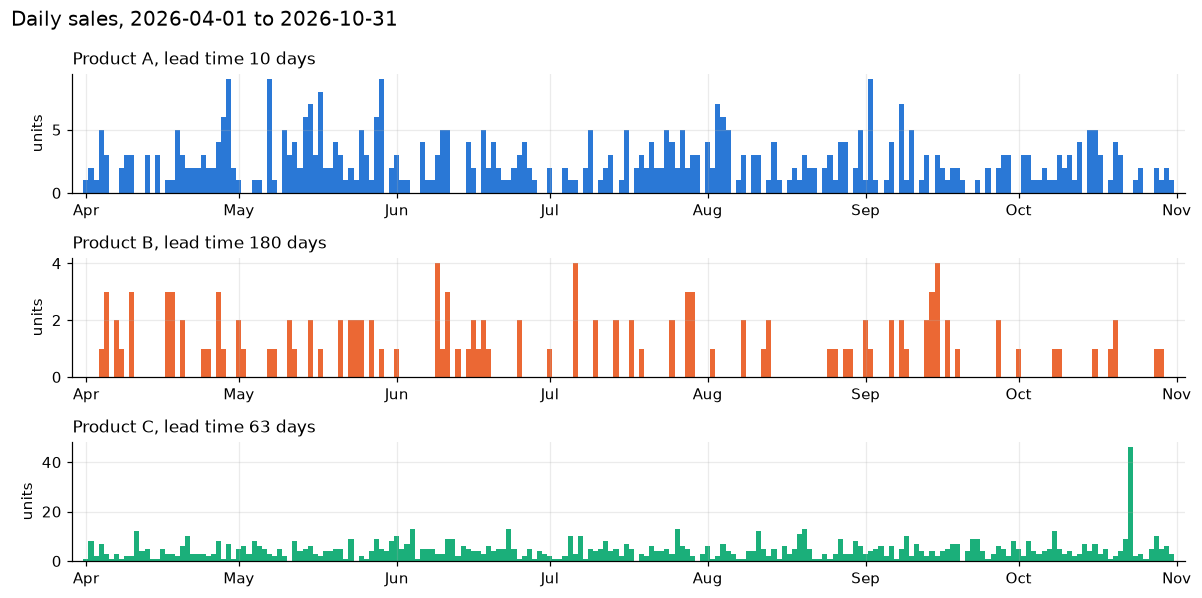

In [6]:
def plot_daily_sales(ax, product):
    """Draw one product's daily sales as bars on the given axes."""
    ax.bar(DAYS, sales[product], width=np.timedelta64(1, "D"),
           color=PRODUCT_COLORS[product], linewidth=0)
    ax.set_title(f"Product {product}, lead time {LEAD_TIME_DAYS[product]} days",
                 loc="left", fontsize=11)
    ax.set_ylabel("units")
    ax.margins(x=0.01)
    # One tick per month, labelled with the month name, under every panel.
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.tick_params(labelbottom=True)


fig, axes = plt.subplots(len(PRODUCTS), 1, figsize=(11, 5.5), sharex=True)
for ax, product in zip(axes, PRODUCTS):
    plot_daily_sales(ax, product)
fig.suptitle(f"Daily sales, {FIRST_DAY} to {LAST_DAY}", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()


### First observations

- **Product A** sells on about three days out of four, usually one to three units, with no trend. It is the textbook case of steady demand.
- **Product B** sells on about four days out of ten, almost always a single unit. Its demand is *intermittent*: the interesting question for B is not how many units, but whether anything sells at all on a given day.
- **Product C** sells on almost every day and faster than A, with larger day-to-day swings and the single 40-unit wholesale order mentioned in the assumptions.

These three shapes are exactly why the products were chosen: a steady one, an intermittent one with a long lead time, and a fast, volatile one. The next section turns the daily sales into a probability model.

## 3. Exploratory Data Analysis

The daily sales are our stand-in for the daily demand $D$ of a product. This section turns the 214 observed days into a probability model of $D$: which values it takes and how often, how far a typical day strays from the mean, and whether one day tells us anything about the next. These are the only facts about $D$ that the rest of the notebook will use.

The tool is the statistical definition of probability: if an event occurred $m$ times in $n$ trials, its probability is estimated by the relative frequency $m / n$. Each day is one trial, so

$$P(D = k) \approx \frac{\text{number of days with exactly } k \text{ units}}{214} .$$

The table of values and their relative frequencies is the **empirical probability mass function** (pmf) of the daily demand.

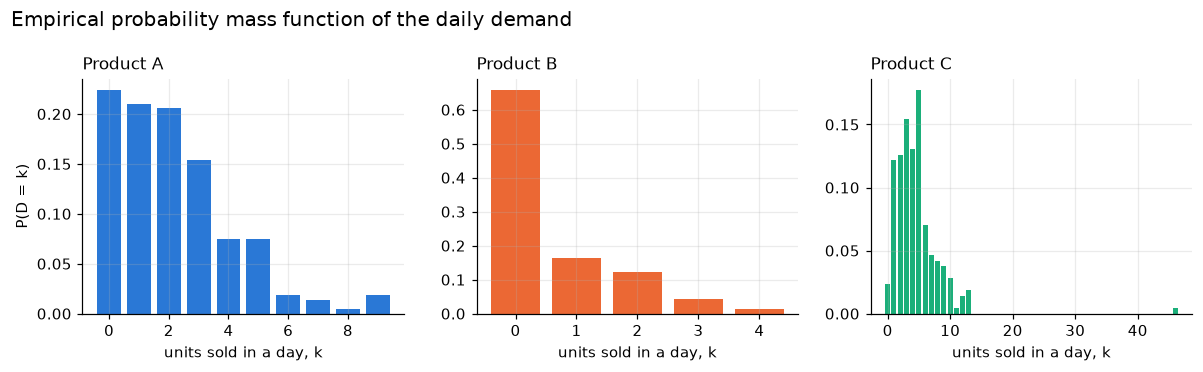

In [7]:
def empirical_pmf(units):
    """Values taken by the daily sales and the relative frequency of each one."""
    values, counts = np.unique(units, return_counts=True)
    return values.astype(int), counts / len(units)


fig, axes = plt.subplots(1, len(PRODUCTS), figsize=(11, 3.4))
for ax, product in zip(axes, PRODUCTS):
    values, probabilities = empirical_pmf(sales[product])
    ax.bar(values, probabilities, color=PRODUCT_COLORS[product], width=0.8)
    ax.set_title(f"Product {product}", loc="left", fontsize=11)
    ax.set_xlabel("units sold in a day, k")
axes[0].set_ylabel("P(D = k)")
fig.suptitle("Empirical probability mass function of the daily demand", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()